In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import seaborn as sns
from scipy.stats import ttest_ind

# reading datasets from UCI Machine Learning Repository
from ucimlrepo import fetch_ucirepo

## Understand Data


### Data Reading

In [21]:
# # 載在本地端跑比較快

# # fetch dataset 
# cdc_diabetes_health_indicators = fetch_ucirepo(id=891) 
  
# # data (as pandas dataframes) 
# X = cdc_diabetes_health_indicators.data.features 
# y = cdc_diabetes_health_indicators.data.targets 
  
# df = pd.concat([X, y], axis=1)

# # Save dataset
# df.to_csv("cdc_diabetes_health_indicators.csv", index=False)

# print("Dataset saved successfully!")


In [22]:
# Data reading
df = pd.read_csv("cdc_diabetes_health_indicators.csv")

# Data understanding
print(df.shape)
print(df.dtypes)

display(df.head())

(253680, 22)
HighBP                  int64
HighChol                int64
CholCheck               int64
BMI                     int64
Smoker                  int64
Stroke                  int64
HeartDiseaseorAttack    int64
PhysActivity            int64
Fruits                  int64
Veggies                 int64
HvyAlcoholConsump       int64
AnyHealthcare           int64
NoDocbcCost             int64
GenHlth                 int64
MentHlth                int64
PhysHlth                int64
DiffWalk                int64
Sex                     int64
Age                     int64
Education               int64
Income                  int64
Diabetes_binary         int64
dtype: object


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,40,1,0,0,0,0,1,...,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,...,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,...,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,...,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,...,0,2,3,0,0,0,11,5,4,0


### Observation of data

In [23]:
#duplicate observations
duplicate_count = df.duplicated().sum()
print("Number of duplicated rows:", duplicate_count)
print("Duplicate percentage:", round(duplicate_count / len(df) * 100, 2), "%")

Number of duplicated rows: 24206
Duplicate percentage: 9.54 %


In [24]:
# Missing values
print("\nMissing Values:")
print(df.isna().sum())


Missing Values:
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
Diabetes_binary         0
dtype: int64


In [25]:
# Check variable ranges
print("\nVariable Ranges:")
display(pd.DataFrame({
    "Min": df.min(),
    "Max": df.max(),
    "Unique": df.nunique()
}))


Variable Ranges:


,Min,Max,Unique
HighBP,0,1,2
HighChol,0,1,2
CholCheck,0,1,2
BMI,12,98,84
Smoker,0,1,2
Stroke,0,1,2
HeartDiseaseorAttack,0,1,2
PhysActivity,0,1,2
Fruits,0,1,2
Veggies,0,1,2


##### outlier detection -- BMI

In [27]:
# Outlier detection -- BMI

# BMI Descriptive Statistics
bmi = df["BMI"]

print(bmi.describe())

Q1 = bmi.quantile(0.25)
Q2 = bmi.quantile(0.50)
Q3 = bmi.quantile(0.75)
IQR = Q3 - Q1

mean = bmi.mean()
std = bmi.std()

print("\nMean:", round(mean, 2))
print("Standard Deviation:", round(std, 2))
print("IQR:", IQR)

# BMI Clinical Categories
bins = [0, 18.5, 25, 30, 35, 40, 50, 60, 70, np.inf]

labels = [
    "Underweight (<18.5)",
    "Normal (18.5-24.9)",
    "Overweight (25-29.9)",
    "Obesity I (30-34.9)",
    "Obesity II (35-39.9)",
    "BMI 40-49.9",
    "BMI 50-59.9",
    "BMI 60-69.9",
    "BMI >=70"
]
bmi_groups = pd.cut(
    df["BMI"],
    bins=bins,
    labels=labels,
    right=False
)
bmi_summary = pd.DataFrame({
    "Count": bmi_groups.value_counts(sort=False),
    "Percentage (%)": bmi_groups.value_counts(
        sort=False, normalize=True
    ) * 100
})
display(bmi_summary.round(2))

count    253680.000000
mean         28.382364
std           6.608694
min          12.000000
25%          24.000000
50%          27.000000
75%          31.000000
max          98.000000
Name: BMI, dtype: float64

Mean: 28.38
Standard Deviation: 6.61
IQR: 7.0


,Count,Percentage (%)
BMI,,
Underweight (<18.5),3127,1.23
Normal (18.5-24.9),68953,27.18
Overweight (25-29.9),93749,36.96
Obesity I (30-34.9),53451,21.07
Obesity II (35-39.9),20663,8.15
BMI 40-49.9,11190,4.41
BMI 50-59.9,1679,0.66
BMI 60-69.9,269,0.11
BMI >=70,599,0.24


In [28]:
# IQR Outlier Detection
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

extreme_lower = Q1 - 3 * IQR
extreme_upper = Q3 + 3 * IQR

outliers = df[(bmi < lower) | (bmi > upper)]

extreme_outliers = df[
    (bmi < extreme_lower) | (bmi > extreme_upper)
]

# Z-score Outlier Detection
z_score = (bmi - mean) / std

z_outliers = df[z_score.abs() > 3]


print("IQR Bounds:", lower, upper)
print("Outliers:", len(outliers))
print("Outlier Rate:", round(len(outliers) / len(df) * 100, 2), "%")

print("\nExtreme IQR Bounds:", extreme_lower, extreme_upper)
print("Extreme Outliers:", len(extreme_outliers))

print("\nNumber of |Z| > 3:", len(z_outliers))
print("Percentage:", round(len(z_outliers) / len(df) * 100, 2), "%")

IQR Bounds: 13.5 41.5
Outliers: 9847
Outlier Rate: 3.88 %

Extreme IQR Bounds: 3.0 52.0
Extreme Outliers: 1707

Number of |Z| > 3: 2963
Percentage: 1.17 %


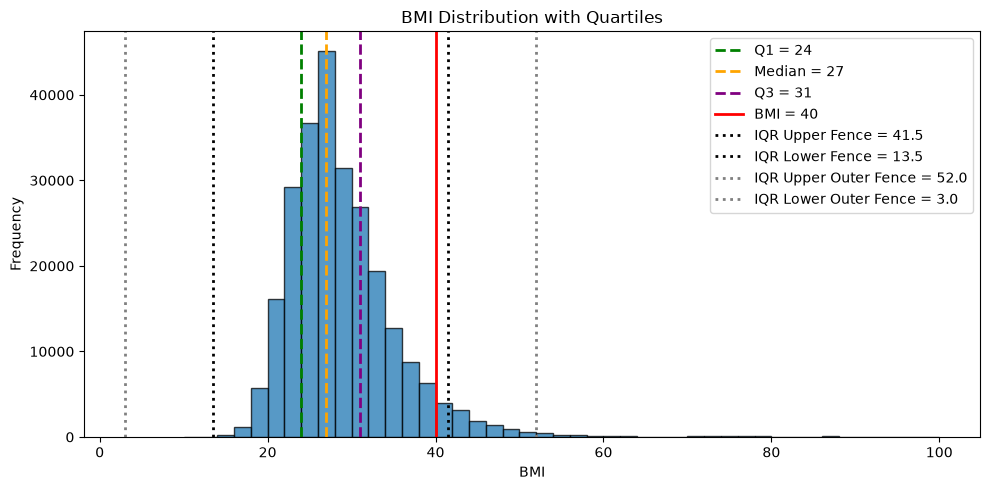

In [29]:
# BMI Distribution

plt.figure(figsize=(10, 5))

# Histogram
plt.hist(bmi, bins=range(10, 101, 2),
         edgecolor="black", alpha=0.75)

# Quartiles
plt.axvline(Q1, color="green", linestyle="--",
            linewidth=2, label=f"Q1 = {Q1:.0f}")

plt.axvline(Q2, color="orange", linestyle="--",
            linewidth=2, label=f"Median = {Q2:.0f}")

plt.axvline(Q3, color="purple", linestyle="--",
            linewidth=2, label=f"Q3 = {Q3:.0f}")

# BMI = 40
plt.axvline(40, color="red", linestyle="-",
            linewidth=2, label="BMI = 40")

# IQR Upper Fence
upper = Q3 + 1.5 * (Q3 - Q1)

plt.axvline(upper, color="black", linestyle=":",
    linewidth=2, label=f"IQR Upper Fence = {upper:.1f}"
)

#IQR Lower Fence
lower = Q1 - 1.5 * (Q3 - Q1)

plt.axvline(lower, color="black", linestyle=":",
    linewidth=2, label=f"IQR Lower Fence = {lower:.1f}"
)

#IQR Upper Outer Fence
outer = Q3 + 3 * (Q3 - Q1)

plt.axvline(outer, color="gray", linestyle=":",
    linewidth=2, label=f"IQR Upper Outer Fence = {outer:.1f}"
)

#IQR Lower Outer Fence
outer_lower = Q1 - 3 * (Q3 - Q1)

plt.axvline(outer_lower, color="gray", linestyle=":",
    linewidth=2, label=f"IQR Lower Outer Fence = {outer_lower:.1f}"
)

plt.xlabel("BMI")
plt.ylabel("Frequency")
plt.title("BMI Distribution with Quartiles")
plt.legend()
plt.tight_layout()
plt.show()

##### Target distribution

In [ ]:
# Target distribution
# 了解 Y = 0/1 的比例
print(df["Diabetes_binary"].value_counts())

print("\nTarget percentage:")
print(
    df["Diabetes_binary"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

## Descriptive statistics

In [37]:
# 先根據不同data type分類
# Variable Groups
target = "Diabetes_binary"

binary_vars = [
    "HighBP", "HighChol", "CholCheck", "Smoker",
    "Stroke", "HeartDiseaseorAttack", "PhysActivity",
    "Fruits", "Veggies", "HvyAlcoholConsump",
    "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Sex"
]

numerical_vars = ["BMI", "MentHlth", "PhysHlth"]

ordinal_vars = ["GenHlth", "Age", "Education", "Income"]

### ppt p11


numerical:
MentHlth 的平均數是 3.18 天，但中位數是 0，且 69.25% 的受訪者回報 0 天。
PhysHlth 也有相同現象，63.09% 的受訪者回報 0 天，但平均數達 4.24 天。
這表示兩個變數都存在明顯的零值集中（Zero Concentration）及右偏分布。

In [ ]:
# Numerical Descriptive Statistics
num_summary = df[numerical_vars].describe().T

num_summary["IQR"] = (
    num_summary["75%"] - num_summary["25%"]
)

display(num_summary.round(2))

# 觀察MentHlth, PhysHlth天數是否大量集中於0天
# Percentage of zero values
zero_rate = (
    df[["MentHlth", "PhysHlth"]]
    .eq(0)
    .mean()
    .mul(100)
)

print(zero_rate.round(2))

,count,mean,std,min,25%,50%,75%,max,IQR
BMI,253680.0,28.38,6.61,12.0,24.0,27.0,31.0,98.0,7.0
MentHlth,253680.0,3.18,7.41,0.0,0.0,0.0,2.0,30.0,2.0
PhysHlth,253680.0,4.24,8.72,0.0,0.0,0.0,3.0,30.0,3.0


MentHlth    69.25
PhysHlth    63.09
dtype: float64


你的 14 個 Binary Predictors 中，我認為最值得注意的是這幾個：
Variable	Percentage (1)	說明
CholCheck	96.27%	幾乎所有人都曾接受膽固醇檢查
AnyHealthcare	95.11%	絕大多數有某種醫療保障
Stroke	4.06%	曾中風者比例較低
HvyAlcoholConsump	5.62%	符合重度飲酒定義的比例較低
NoDocbcCost	8.42%	曾因費用因素而無法就醫的比例較低
PhysActivity	75.65%	多數受訪者回報有身體活動

In [43]:
# Binary Descriptive Statistics
binary_summary = pd.DataFrame({
    "Count (1)": df[binary_vars].sum(),
    "Percentage (1)": df[binary_vars].mean() * 100,
    "Count (0)": (df[binary_vars] == 0).sum()
})

display(binary_summary.round(2))

,Count (1),Percentage (1),Count (0)
HighBP,108829,42.90,144851
HighChol,107591,42.41,146089
CholCheck,244210,96.27,9470
Smoker,112423,44.32,141257
Stroke,10292,4.06,243388
HeartDiseaseorAttack,23893,9.42,229787
PhysActivity,191920,75.65,61760
Fruits,160898,63.43,92782
Veggies,205841,81.14,47839
HvyAlcoholConsump,14256,5.62,239424


Variable	Median	Q1	Q3	值得注意的結果
GenHlth	2	2	3	52.98% 回報 Excellent 或 Very Good
Age	8	6	10	最常見的年齡級距為第 9 組，占 13.10%
Education	5	4	6	第 6 級占 42.31%
Income	7	5	8	最高收入級距占 35.63%

In [46]:
# Ordinal Descriptive Statistics
ordinal_summary = df[ordinal_vars].agg(
    ["min", "median", "max"]
).T

ordinal_summary["Q1"] = df[ordinal_vars].quantile(0.25)
ordinal_summary["Q3"] = df[ordinal_vars].quantile(0.75)

display(ordinal_summary)

# Ordinal Category Frequencies
for col in ordinal_vars:
    display(
        df[col].value_counts(
            normalize=True
        ).sort_index().mul(100).round(2)
    )

,min,median,max,Q1,Q3
GenHlth,1.0,2.0,5.0,2.0,3.0
Age,1.0,8.0,13.0,6.0,10.0
Education,1.0,5.0,6.0,4.0,6.0
Income,1.0,7.0,8.0,5.0,8.0


GenHlth
1    17.86
2    35.12
3    29.82
4    12.44
5     4.76
Name: proportion, dtype: float64

Age
1      2.25
2      3.00
3      4.38
4      5.45
5      6.37
6      7.81
7     10.37
8     12.15
9     13.10
10    12.69
11     9.28
12     6.30
13     6.84
Name: proportion, dtype: float64

Education
1     0.07
2     1.59
3     3.74
4    24.74
5    27.56
6    42.31
Name: proportion, dtype: float64

Income
1     3.87
2     4.64
3     6.30
4     7.94
5    10.20
6    14.38
7    17.04
8    35.63
Name: proportion, dtype: float64

##### plot

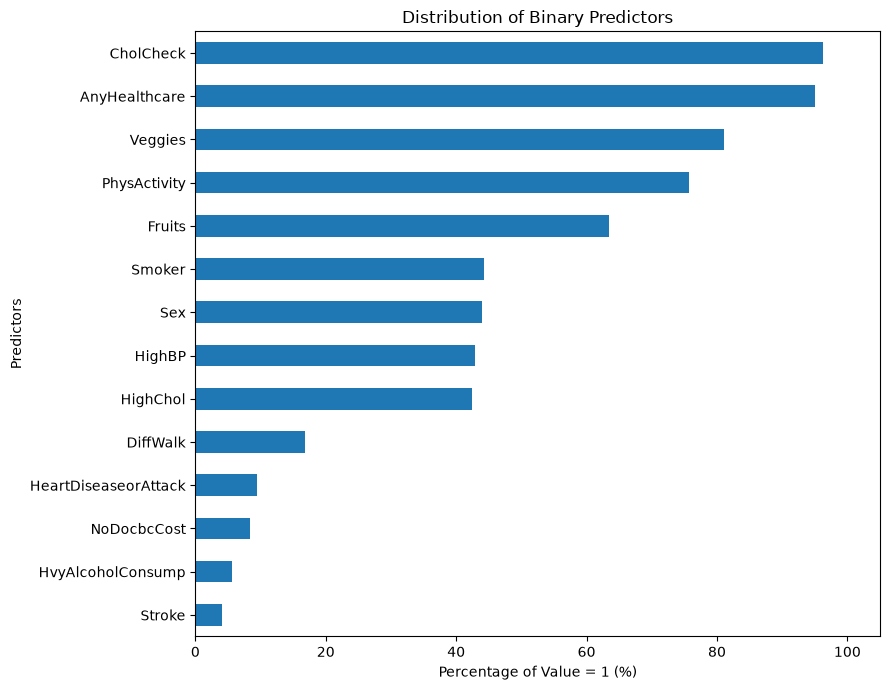

In [47]:
# Binary Variables Distribution
binary_pct = (
    df[binary_vars]
    .mean()
    .mul(100)
    .sort_values()
)

plt.figure(figsize=(9, 7))

binary_pct.plot(kind="barh")

plt.xlabel("Percentage of Value = 1 (%)")
plt.ylabel("Predictors")
plt.title("Distribution of Binary Predictors")
plt.xlim(0, 105)
plt.tight_layout()
plt.show()

## EDA

### Correlation Anlysis

1. Predictor vs. Predictor：了解 predictors 之間的相關程度，找出潛在的 Multicollinearity。
2. Predictor vs. Target：了解哪些 predictors 與 Diabetes_binary 存在較強的單變數關聯。
3. Statistical Tests：根據變數類型進行適當的統計檢定，例如 Welch's t-test、Chi-square Test。
需要特別強調：這些都是初步關聯分析，不會在此階段根據相關係數或 p-value 刪除 predictors。

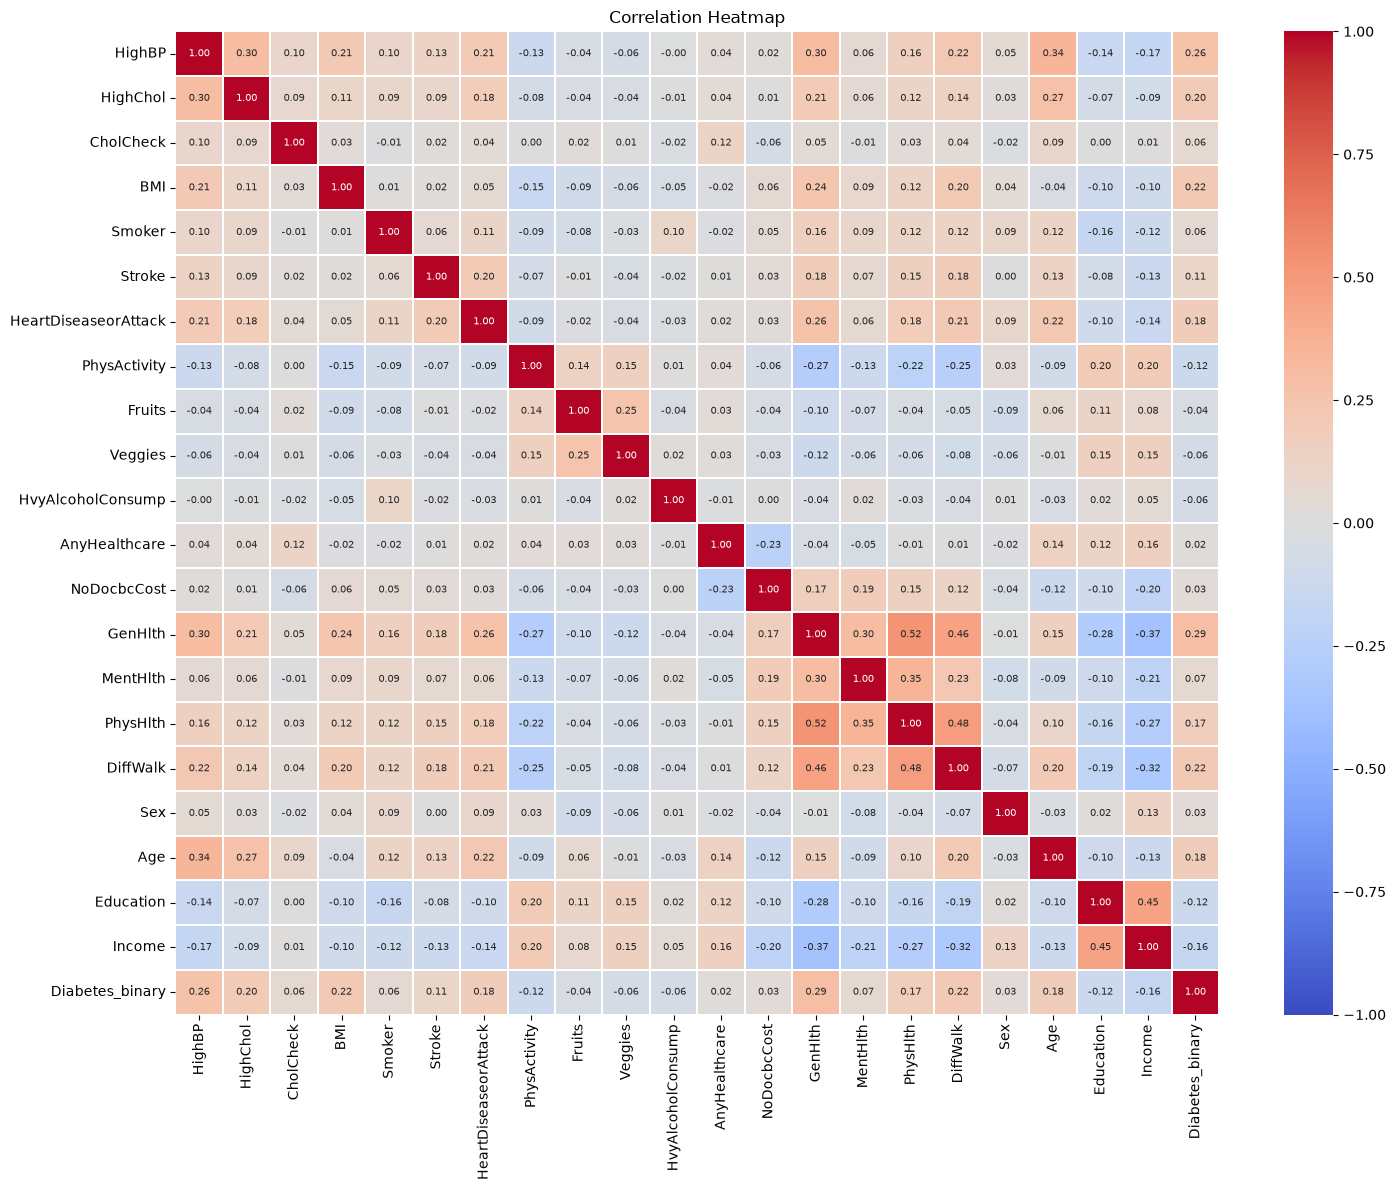

In [49]:
# Correlation matrix
corr = df.corr(method="pearson")

# Correlation Heatmap
plt.figure(figsize=(15, 12))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.3,
    annot_kws={"size": 7}
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [50]:
# Predictor-to-Predictor Correlation
X_corr = df.drop(columns="Diabetes_binary").corr()

# Keep upper triangle only
upper = X_corr.where(
    np.triu(np.ones(X_corr.shape), k=1).astype(bool)
)

# Extract and rank correlations
corr_pairs = (
    upper.stack()
    .rename("Correlation")
    .reset_index()
)

corr_pairs.columns = [
    "Predictor 1", "Predictor 2", "Correlation"
]

corr_pairs["Absolute Correlation"] = (
    corr_pairs["Correlation"].abs()
)

corr_pairs = corr_pairs.sort_values(
    "Absolute Correlation",
    ascending=False
)

display(corr_pairs.head(15).round(3))

,Predictor 1,Predictor 2,Correlation,Absolute Correlation
288,GenHlth,PhysHlth,0.524,0.524
331,PhysHlth,DiffWalk,0.478,0.478
289,GenHlth,DiffWalk,0.457,0.457
419,Education,Income,0.449,0.449
293,GenHlth,Income,-0.370,0.370
309,MentHlth,PhysHlth,0.354,0.354
18,HighBP,Age,0.344,0.344
356,DiffWalk,Income,-0.320,0.320
287,GenHlth,MentHlth,0.302,0.302
13,HighBP,GenHlth,0.301,0.301


,Correlation
Income,-0.1639
Education,-0.1245
PhysActivity,-0.1181
HvyAlcoholConsump,-0.0571
Veggies,-0.0566
Fruits,-0.0408
AnyHealthcare,0.0163
Sex,0.0314
NoDocbcCost,0.0314
Smoker,0.0608


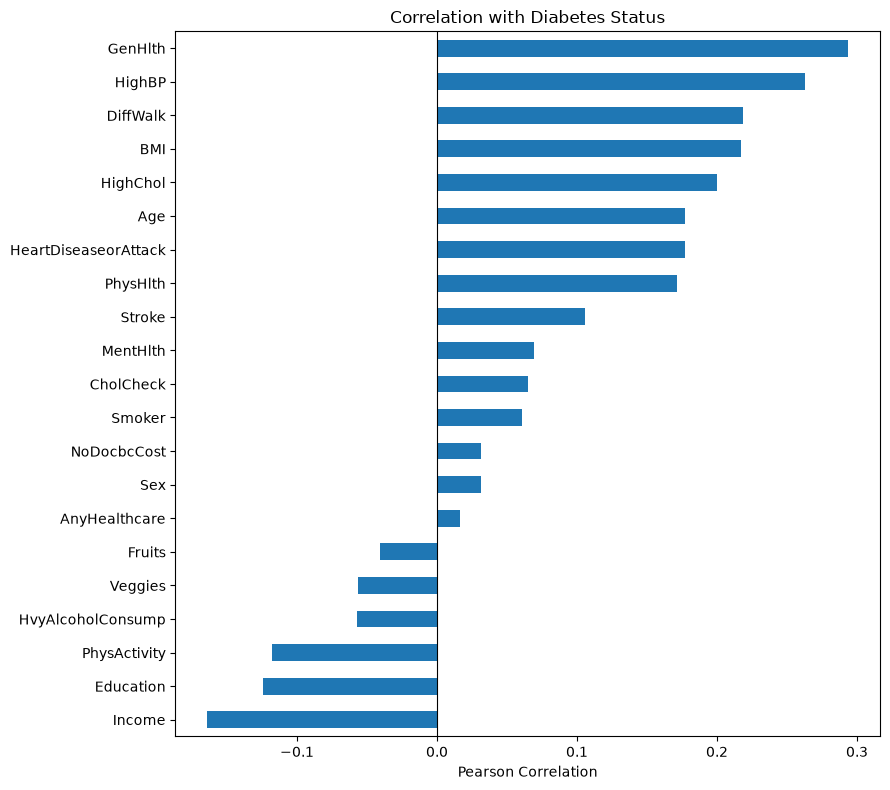

In [51]:
# Correlation with Target
target_corr = (
    corr["Diabetes_binary"]
    .drop("Diabetes_binary")
    .sort_values()
)

display(target_corr.to_frame("Correlation").round(4))

# Horizontal bar chart
plt.figure(figsize=(9, 8))

target_corr.plot(kind="barh")

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Pearson Correlation")
plt.title("Correlation with Diabetes Status")
plt.tight_layout()
plt.show()

In [ ]:
# 針對不同變數類型進行統計檢定

numerical_vars = ["BMI", "MentHlth", "PhysHlth"]

t_results = []

for col in numerical_vars:
    group0 = df.loc[df["Diabetes_binary"] == 0, col]
    group1 = df.loc[df["Diabetes_binary"] == 1, col]

    t_stat, p_value = ttest_ind(
        group0, group1, equal_var=False
    )

    t_results.append({
        "Variable": col,
        "Mean (Y=0)": group0.mean(),
        "Mean (Y=1)": group1.mean(),
        "Mean Difference": group1.mean() - group0.mean(),
        "t-statistic": t_stat,
        "p-value": p_value
    })

t_results = pd.DataFrame(t_results)

display(t_results.round(4))